# Сравнение детекторов аномалий траектории

In [1]:
TORCH_CUDA_INDEX = "https://download.pytorch.org/whl/cu124"
ALLOWED_STATUS = ("move", "anomaly")

TEST_SPLIT_1 = 0.6
TEST_SPLIT_2 = 0.8
MCC_BAND = 0.02
AR_LAGS = 2
PLOT_TAIL = 50_000
MAP_FIGSIZE = (22.0, 11.0)

## Чтение и предобработка данных

Исходный файл csv задаёт последовательность записей с полями времени, координат и статуса. После чтения строится очищенный ряд наблюдений и две пары выборок «обучение / тест» с разными долями обучения.

После загрузки CSV имеем индексы $j=0,\ldots,M-1$. Сырые поля: $t_j$ (time), $\varphi_j$ (lat), $\lambda_j$ (lon), $y_j$ (status). Допустимые значения метки: $y_j\in\{\mathrm{move},\mathrm{anomaly},\ldots\}$; в эксперименте остаются только $\mathrm{move}$ и $\mathrm{anomaly}$. Для метрик классификации положительный класс — аномалия ($y_i=\mathrm{anomaly}$); в столбце label она кодируется нулём, штатный ход — единицей.

**1. Отбор столбцов.** Оставляем только
$$(t_i,\varphi_i,\lambda_i,y_i)_{i=0}^{N-1},$$
где $t_i$ — время, $\varphi_i$ — широта, $\lambda_i$ — долгота, $y_i$ — метка класса.

**2. Валидные координаты.** Исключаются пропуски, нечисловые координаты, выход за допустимые пределы WGS-84 и точки «нулевого» GPS:
$$\mathcal{J}_1=\{i:\ \varphi_i,\lambda_i\ \text{конечны},\ -90\le\varphi_i\le 90,\ -180\le\lambda_i\le 180,\ (\varphi_i,\lambda_i)\neq(0,0)\}.$$

**3. Бинарная задача.** Остаются только штатный ход и аномалия:
$$\mathcal{J}_2=\{i\in\mathcal{J}_1:\ y_i\in\{\mathrm{move},\mathrm{anomaly}\}\}.$$

**4. Упорядочивание.** На $\mathcal{J}_2$ задаётся сортировка по возрастанию $t_i$. Индекс $i=0$ — первая валидная точка ряда.

**5. Локальная ENU (м).** Опорная точка — первая валидная точка: $(\varphi_0,\lambda_0)=(\varphi_{0},\lambda_{0})$ в нумерации после шагов 1–4. Координаты WGS-84 переводятся в плоскость «восток–север» (WGS-84 $\to$ ECEF $\to$ ENU):
$$(x_i,n_i)\equiv(E_i,N_i)=\mathrm{ENU}(\varphi_i,\lambda_i\mid\varphi_0,\lambda_0).$$
Поля $\varphi_i,\lambda_i$ сохраняются; столбцы $x_i$, $n_i$ добавляются в таблицу (метка класса по-прежнему $y_i$).

**6. Обрезка по крайним $\mathrm{move}$.** Пусть
$$\mathcal{I}_{\mathrm{move}}=\{i:\ y_i=\mathrm{move}\},\quad i_{\min}=\min\mathcal{I}_{\mathrm{move}},\quad i_{\max}=\max\mathcal{I}_{\mathrm{move}}.$$
Рабочий ряд — срез $i_{\min}\le i\le i_{\max}$ (первая и последняя точки ряда — $\mathrm{move}$); координаты $(x_i,n_i)$ не пересчитываются.

**7. Разбиение train / test.** Для доли обучения $\rho\in(0,1)$ (в блокноте $\rho=\texttt{TEST\_SPLIT\_1}$ или $\texttt{TEST\_SPLIT\_2}$) при длине ряда $N$ задаётся пороговый индекс
$$k_0=\lfloor\rho N\rfloor.$$
Граница разбиения — первый индекс штатного хода не левее $k_0$:
$$k=\min\{i\ge k_0:\ y_i=\mathrm{move}\}.$$
Если $y_{k_0}=\mathrm{move}$, то $k=k_0$. Обучение: индексы $[0,k)$, тест: $[k,N)$. Так граница не попадает внутрь чисто аномального фрагмента без соседнего $\mathrm{move}$.

In [2]:
import os
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.special import logsumexp
from scipy.stats import chi2
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from app.evaluation import GeospatialMetrics, TrajectoryMetrics, TrajectorySeries
from app.geo.local_enu import LocalEnuConverter
from app.viz import plot_track_maps
from statsmodels.tsa.arima.model import ARIMA


path_root = Path.cwd().parent
path_data = path_root / "data" / "2.csv"

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda:0")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    DEVICE = torch.device("cpu")
torch.set_num_threads(max(1, min(8, os.cpu_count() or 1)))

print(f"Корень: {path_root}")
print(f"Файл: {path_data}")
print(f"PyTorch {torch.__version__}, устройство {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(DEVICE)}")


Корень: C:\Users\svaga\PycharmProjects\statistical_researchs
Файл: C:\Users\svaga\PycharmProjects\statistical_researchs\data\2.csv
PyTorch 2.6.0+cu124, устройство cuda:0
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [3]:
def nfmt(value: int) -> str:
    """Форматирует целое число с разделителем тысяч (пробел).

    Args:
        value: целое значение для вывода.

    Returns:
        str: строка вида «1 234 567».
    """
    return f"{int(value):,}".replace(",", " ")


def fmt_num(value: float, decimals: int = 2) -> str:
    """Число; при |value| >= 1000 — разделитель тысяч «_».

    Args:
        value: Значение для вывода.
        decimals: Число знаков после запятой (0 — целое).

    Returns:
        str: Отформатированная строка или «—» для нечисловых значений.
    """
    if value is None or not np.isfinite(float(value)):
        return "—"
    number = float(value)
    negative = number < 0
    number = abs(number)
    if number < 1000:
        text = f"{number:.{decimals}f}" if decimals else str(int(round(number)))
        if "." in text:
            text = text.rstrip("0").rstrip(".")
        return ("-" if negative else "") + text
    if decimals == 0:
        body = f"{int(round(number)):,}".replace(",", "_")
    else:
        whole = int(number)
        fraction = number - whole
        fraction_text = f"{fraction:.{decimals}f}".split(".")[1].rstrip("0")
        body = f"{whole:,}".replace(",", "_")
        if fraction_text:
            body = f"{body}.{fraction_text}"
    return ("-" if negative else "") + body


def select_trajectory_columns(raw: pd.DataFrame) -> pd.DataFrame:
    """Оставляет столбцы time, lat, lon и переименовывает status в y.

    Args:
        raw: таблица из data/2.csv.

    Returns:
        pd.DataFrame: столбцы time, lat, lon, y.
    """
    return raw.loc[:, ["time", "lat", "lon", "status"]].rename(columns={"status": "y"}).copy()


def coerce_coordinate_columns(frame: pd.DataFrame) -> pd.DataFrame:
    """Приводит lat и lon к числовому типу (нечисловые значения → NaN).

    Args:
        frame: таблица с столбцами lat, lon.

    Returns:
        pd.DataFrame: копия с числовыми lat, lon.
    """
    result = frame.copy()
    result["lat"] = pd.to_numeric(result["lat"], errors="coerce")
    result["lon"] = pd.to_numeric(result["lon"], errors="coerce")
    return result


def filter_finite_coordinates(frame: pd.DataFrame) -> pd.DataFrame:
    """Удаляет строки с пропусками в lat или lon.

    Args:
        frame: таблица с lat, lon.

    Returns:
        pd.DataFrame: только строки с конечными координатами.
    """
    mask = frame["lat"].notna() & frame["lon"].notna()
    return frame.loc[mask].reset_index(drop=True)


def filter_coordinates_wgs84(frame: pd.DataFrame) -> pd.DataFrame:
    """Удаляет строки с координатами вне допустимых пределов WGS-84.

    Args:
        frame: таблица с lat, lon.

    Returns:
        pd.DataFrame: lat в [-90, 90], lon в [-180, 180].
    """
    mask = frame["lat"].between(-90.0, 90.0) & frame["lon"].between(-180.0, 180.0)
    return frame.loc[mask].reset_index(drop=True)


def filter_nonzero_gps(frame: pd.DataFrame) -> pd.DataFrame:
    """Удаляет точки «нулевого» GPS (lat, lon) = (0, 0).

    Args:
        frame: таблица с lat, lon.

    Returns:
        pd.DataFrame: отфильтрованный ряд.
    """
    mask = ~((frame["lat"] == 0.0) & (frame["lon"] == 0.0))
    return frame.loc[mask].reset_index(drop=True)


def filter_allowed_status(frame: pd.DataFrame, allowed: tuple[str, ...]) -> pd.DataFrame:
    """Оставляет только метки из allowed (move, anomaly).

    Args:
        frame: таблица со столбцом y.
        allowed: допустимые строковые значения status.

    Returns:
        pd.DataFrame: отфильтрованный ряд.
    """
    labels = frame["y"].astype(str)
    return frame.loc[labels.isin(allowed)].reset_index(drop=True)


def sort_by_time(frame: pd.DataFrame) -> pd.DataFrame:
    """Сортирует ряд по возрастанию time (стабильная сортировка).

    Args:
        frame: таблица со столбцом time.

    Returns:
        pd.DataFrame: упорядоченный ряд.
    """
    order = np.argsort(pd.to_datetime(frame["time"]).to_numpy(), kind="mergesort")
    return frame.iloc[order].reset_index(drop=True)


def attach_local_enu(frame: pd.DataFrame) -> pd.DataFrame:
    """Добавляет столбцы x, n — локальная ENU (м) от первой точки ряда.

    Args:
        frame: таблица с lat, lon.

    Returns:
        pd.DataFrame: с добавленными x, n.
    """
    result = frame.copy()
    enu = LocalEnuConverter.from_first_point(result["lat"].iloc[0], result["lon"].iloc[0])
    east, north = enu.to_local_xy(result["lat"].to_numpy(), result["lon"].to_numpy())
    result["x"] = east
    result["n"] = north
    return result


def trim_to_extreme_move(frame: pd.DataFrame) -> pd.DataFrame:
    """Обрезает ряд от первой до последней точки со статусом move.

    Args:
        frame: таблица со столбцом y.

    Returns:
        pd.DataFrame: срез между крайними move.

    Raises:
        RuntimeError: если в ряду нет точек move.
    """
    is_move = frame["y"].astype(str).to_numpy() == "move"
    if not np.any(is_move):
        raise RuntimeError("После фильтрации нет точек move.")
    move_idx = np.flatnonzero(is_move)
    return frame.iloc[move_idx[0] : move_idx[-1] + 1].reset_index(drop=True)


def attach_binary_label(frame: pd.DataFrame) -> pd.DataFrame:
    """Добавляет столбец label для TrajectoryMetrics / TrajectorySeries.

    Положительный класс в метриках (MCC, precision, recall) — anomaly. В этом
    проекте он кодируется нулём (не единицей): anomaly → 0, move → 1. См.
    ClassificationMetrics и anomaly_mask (label == 0).

    Args:
        frame: таблица со столбцом y (строки move / anomaly).

    Returns:
        pd.DataFrame: с столбцом label (float).
    """
    result = frame.copy()
    result["label"] = np.where(result["y"].astype(str) == "anomaly", 0.0, 1.0)
    return result


def split_train_test_move(frame: pd.DataFrame, train_fraction: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Делит ряд на обучение [0, k) и тест [k, N); граница k — первый move с индексом i >= floor(rho*N).

    Args:
        frame: предобработанный ряд с столбцом y (move / anomaly).
        train_fraction: доля обучения rho из (0, 1), как TEST_SPLIT_1 или TEST_SPLIT_2.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: (train, test).

    Raises:
        ValueError: если train_fraction не в (0, 1).
        RuntimeError: если ряд слишком короткий, нет подходящего move или выборка пуста.
    """
    if not 0.0 < train_fraction < 1.0:
        raise ValueError("train_fraction должен быть в (0, 1).")
    n = len(frame)
    if n < 2:
        raise RuntimeError("Слишком короткий ряд для разбиения.")
    k0 = int(np.floor(train_fraction * n))
    k0 = min(max(k0, 1), n - 1)
    labels = frame["y"].astype(str).to_numpy()
    move_from_k0 = np.flatnonzero((np.arange(n) >= k0) & (labels == "move"))
    if move_from_k0.size == 0:
        raise RuntimeError(f"Нет move для границы при rho={train_fraction}.")
    k = int(move_from_k0[0])
    train = frame.iloc[:k].reset_index(drop=True)
    test = frame.iloc[k:].reset_index(drop=True)
    if len(train) == 0 or len(test) == 0:
        raise RuntimeError(f"Пустая выборка при rho={train_fraction}, k={k}, N={n}.")
    return train, test


def describe_split(name: str, train: pd.DataFrame, test: pd.DataFrame) -> None:
    """Печатает размер и доли классов anomaly и move для обучения и теста.

    Args:
        name: заголовок сценария (например, df1 и доля rho).
        train: обучающая выборка.
        test: тестовая выборка.
    """
    for part_name, part in (("обучение", train), ("тест", test)):
        labels = part["y"].astype(str)
        n = len(part)
        p_anom = float((labels == "anomaly").mean())
        p_move = float((labels == "move").mean())
        print(
            f"{name}: {part_name:<9} {nfmt(n):>10} точек   "
            f"anomaly {p_anom:6.1%}   move {p_move:6.1%}"
        )


raw_full = pd.read_csv(path_data)
frame = select_trajectory_columns(raw_full)
frame = coerce_coordinate_columns(frame)
frame = filter_finite_coordinates(frame)
frame = filter_coordinates_wgs84(frame)
frame = filter_nonzero_gps(frame)
frame = filter_allowed_status(frame, ALLOWED_STATUS)
frame = sort_by_time(frame)
frame = attach_local_enu(frame)
frame = trim_to_extreme_move(frame)
frame = attach_binary_label(frame)
train_1, test_1 = split_train_test_move(frame, TEST_SPLIT_1)
train_2, test_2 = split_train_test_move(frame, TEST_SPLIT_2)

df1 = {"train": train_1, "test": test_1}
df2 = {"train": train_2, "test": test_2}

print(f"Исходный CSV: {nfmt(len(raw_full))} строк, после предобработки: {nfmt(len(frame))}.")
describe_split("df1 (rho={:.0%})".format(TEST_SPLIT_1), train_1, test_1)
describe_split("df2 (rho={:.0%})".format(TEST_SPLIT_2), train_2, test_2)

Исходный CSV: 419 453 строк, после предобработки: 252 818.
df1 (rho=60%): обучение     166 555 точек   anomaly  69.5%   move  30.5%
df1 (rho=60%): тест          86 263 точек   anomaly  27.5%   move  72.5%
df2 (rho=80%): обучение     202 254 точек   anomaly  61.2%   move  38.8%
df2 (rho=80%): тест          50 564 точек   anomaly  31.0%   move  69.0%


## Используемые метрики

### Коэффициент корреляции Мэттьюса (MCC)

**Коэффициент корреляции Мэттьюса** (Matthews correlation coefficient, MCC) — коэффициент корреляции Пирсона между двумя бинарными векторами: эталонной разметкой и предсказанием (каждая компонента кодируется как 0 или 1). Эквивалентно он выражается через четыре числа таблицы сопряжённости $TP$, $FP$, $FN$, $TN$ и принимает значения от $-1$ до $1$.

**Используется в задачах** бинарной классификации, в том числе при сильном дисбалансе классов: оценка предсказаний структуры белка, медицинская диагностика, обнаружение аномалий, сравнение порогов и моделей, когда accuracy и доля «большого» класса малоинформативны.

**Источник:** Chicco D., Jurman G. *The advantages of the Matthews correlation coefficient (MCC) over F1 score and accuracy in binary classification evaluation* // BMC Genomics. 2020. Vol. 21, Art. 6. Open access: [10.1186/s12864-019-6413-7](https://link.springer.com/article/10.1186/s12864-019-6413-7). (В статье отмечено, что MCC изначально предложен B. W. Matthews в 1975 г.; в статье приведены математические свойства и сравнение с accuracy и $F_1$.)

**Основное преимущество:** метрика одновременно учитывает все четыре ячейки таблицы сопряжённости и симметрично отражает цену ложных срабатываний и пропусков; при дисбалансе классов тривиальные предсказания «всегда отрицательный» или «всегда положительный» класс обычно дают MCC около нуля, тогда как accuracy может оставаться высокой.

**Для положительного класса** (в этом блокноте положительный класс — **аномалия**, $y_i=0$, бинарная метка $a_i=\mathbf{1}[y_i=0]$; предсказание $\hat a_i=\mathbf{1}[\hat y_i=0]$):

$$
\mathrm{MCC}=\frac{TP\cdot TN - FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}},
$$
где:\
$TP=\sum_i \mathbf{1}[a_i=1\land \hat a_i=1]$,\
$FP=\sum_i \mathbf{1}[a_i=0\land \hat a_i=1]$,\
$FN=\sum_i \mathbf{1}[a_i=1\land \hat a_i=0]$,\
$TN=\sum_i \mathbf{1}[a_i=0\land \hat a_i=0]$.

**Интерпретация:** $\mathrm{MCC}\in[-1,1]$; $1$ — полное совпадение масок; $0$ — согласие на уровне случайного предсказания при тех же маргинальных долях классов; отрицательные значения — систематическое расхождение хуже случайного. Если знаменатель равен нулю (например, в выборке или в предсказании только один класс), MCC в строгом смысле не определён; в коде этого блокнота в таком случае принимается $0$.

### Distance loss

Геопространственная метрика: насколько расходятся длины эталонной и предсказанной траектории (в метрах). Длина ломаной — сумма геодезических звеньев $d_{\mathrm{geo}}$; distance loss — модуль разности:

$$
L(T)=\sum_i d_{\mathrm{geo}}(p_i,p_{i+1}), \qquad DL=\bigl|L_{\mathrm{pred}}-L_{\mathrm{ref}}\bigr|.
$$

$L_{\mathrm{ref}}$ строится по $G$ (штатные точки и линейная интерполяция в аномалиях между соседними штатными). $L_{\mathrm{pred}}$ — по $P$: в ломаную входят только точки, принятые за штатный ход ($\hat y_i\neq 0$); пропуски не интерполируются, соседние принятые точки соединяются напрямую. На тесте $DL$ также считается через на заполненных траекториях; при выборе порога по MCC в полосе близкого значения MCC минимизируется операционный distance loss (длина по принятым move-точкам).

In [4]:
def trajectory_series_pair(frame: pd.DataFrame, predicted_anomaly: np.ndarray) -> tuple[TrajectorySeries, TrajectorySeries]:
    """Собирает prediction и ground truth для TrajectoryMetrics.

    Args:
        frame: Строки test с полями time, lat, lon, y.
        predicted_anomaly: True, если модель объявила anomaly.

    Returns:
        tuple[TrajectorySeries, TrajectorySeries]: (prediction, ground_truth).
    """
    ground_anomaly = frame["y"].astype(str).to_numpy() == "anomaly"
    truth = np.where(ground_anomaly, 0.0, 1.0)
    predicted = np.where(predicted_anomaly, 0.0, 1.0)
    time = frame["time"].to_numpy()
    lon = frame["lon"].to_numpy(dtype=float)
    lat = frame["lat"].to_numpy(dtype=float)
    ground_truth = TrajectorySeries(time, lon, lat, truth)
    prediction = TrajectorySeries(time, lon, lat, predicted)
    return prediction, ground_truth


def slice_trajectory_series(series: TrajectorySeries, tail: int) -> TrajectorySeries:
    """Хвост TrajectorySeries для карты (последние tail точек).

    Args:
        series: Исходный ряд.
        tail: Число точек с конца.

    Returns:
        TrajectorySeries: Срез хвоста.
    """
    count = min(int(tail), len(series.time))
    return TrajectorySeries(
        series.time[-count:],
        series.lon[-count:],
        series.lat[-count:],
        series.label[-count:],
    )


def evaluate_test(frame: pd.DataFrame, predicted_anomaly: np.ndarray) -> dict[str, float]:
    """Считает на тесте метрики из Отчёта (TrajectoryMetrics.compute_all).

    Args:
        frame: Тестовый DataFrame.
        predicted_anomaly: Маска предсказанных anomaly.

    Returns:
        dict[str, float]: Гео-, временные и классификационные метрики test.
    """
    prediction, ground_truth = trajectory_series_pair(frame, predicted_anomaly)
    return TrajectoryMetrics.compute_all(prediction, ground_truth)

from app.evaluation.classification_metrics import ClassificationMetrics


def operational_path_length_m(east_m: np.ndarray, north_m: np.ndarray, move_mask: np.ndarray) -> float:
    """Длина ломаной в ENU только по точкам move (без интерполяции).

    Args:
        east_m: Восток, м.
        north_m: Север, м.
        move_mask: True для штатного хода.

    Returns:
        float: Длина в метрах.
    """
    move = np.asarray(move_mask, dtype=bool)
    east = np.asarray(east_m, dtype=np.float64)[move]
    north = np.asarray(north_m, dtype=np.float64)[move]
    if east.size < 2:
        return 0.0
    return float(np.sum(np.hypot(np.diff(east), np.diff(north))))


def operational_distance_loss_m(
    east_m: np.ndarray,
    north_m: np.ndarray,
    ground_truth_anomaly: np.ndarray,
    predicted_anomaly: np.ndarray,
) -> float:
    """Операционный |L_pred - L_ref| по move-точкам в ENU.

    Args:
        east_m: Восток, м.
        north_m: Север, м.
        ground_truth_anomaly: True для anomaly в разметке.
        predicted_anomaly: True для предсказанной anomaly.

    Returns:
        float: Distance loss в метрах.
    """
    gt_anomaly = np.asarray(ground_truth_anomaly, dtype=bool)
    pred_anomaly = np.asarray(predicted_anomaly, dtype=bool)
    reference_m = operational_path_length_m(east_m, north_m, ~gt_anomaly)
    predicted_m = operational_path_length_m(east_m, north_m, ~pred_anomaly)
    return float(abs(predicted_m - reference_m))


def _threshold_record(
    tau: float,
    predicted_anomaly: np.ndarray,
    frame: pd.DataFrame,
    ground_truth_anomaly: np.ndarray,
) -> dict[str, float]:
    time = frame["time"].to_numpy()
    lon = frame["lon"].to_numpy(dtype=float)
    lat = frame["lat"].to_numpy(dtype=float)
    east_m = frame["x"].to_numpy(dtype=float)
    north_m = frame["n"].to_numpy(dtype=float)
    labels_pred = np.where(predicted_anomaly, 0.0, 1.0)
    labels_gt = np.where(ground_truth_anomaly, 0.0, 1.0)
    prediction = TrajectorySeries(time, lon, lat, labels_pred)
    ground_truth = TrajectorySeries(time, lon, lat, labels_gt)
    precision, recall, f1, mcc = ClassificationMetrics.point_scores(prediction, ground_truth)
    loss_m = operational_distance_loss_m(east_m, north_m, ground_truth_anomaly, predicted_anomaly)
    return {
        "tau": float(tau),
        "mcc": float(mcc),
        "f1": float(f1),
        "precision": float(precision),
        "recall": float(recall),
        "loss_m": float(loss_m),
    }


def select_anomaly_threshold(
    frame: pd.DataFrame,
    scores: np.ndarray,
    mcc_band: float,
    n_quantiles: int = 180,
) -> dict[str, float]:
    """Подбирает порог score на train: max MCC, в полосе mcc_band — min операционный DL.

    Args:
        frame: Обучающий DataFrame (time, lat, lon, x, n, y).
        scores: Anomaly score (больше — подозрительнее).
        mcc_band: Допуск по MCC относительно лучшего значения.
        n_quantiles: Число квантилей в сетке порогов.

    Returns:
        dict[str, float]: tau, train_mcc, train_f1, train_dl_m, best_mcc, band_size.

    Raises:
        RuntimeError: Нет допустимых порогов.
    """
    scores = np.nan_to_num(np.asarray(scores, dtype=float), nan=0.0, posinf=1e12, neginf=0.0)
    ground_truth_anomaly = frame["y"].astype(str).to_numpy() == "anomaly"
    candidates = np.unique(np.quantile(scores, np.linspace(0.01, 0.995, n_quantiles)))
    records = [_threshold_record(float(tau), scores > tau, frame, ground_truth_anomaly) for tau in candidates]
    usable = [r for r in records if np.isfinite(r["loss_m"]) and np.isfinite(r["mcc"])]
    if not usable:
        raise RuntimeError("Нет конечного MCC и distance loss для выбора порога.")
    best_mcc = max(r["mcc"] for r in usable)
    band = [r for r in usable if r["mcc"] >= best_mcc - mcc_band - 1e-12]
    band.sort(key=lambda r: (r["loss_m"], -r["mcc"], -r["f1"], r["tau"]))
    chosen = band[0]
    return {
        "tau": chosen["tau"],
        "train_mcc": chosen["mcc"],
        "train_f1": chosen["f1"],
        "train_dl_m": chosen["loss_m"],
        "best_mcc": float(best_mcc),
        "band_size": float(len(band)),
    }


# Порядок и подписи.
TEST_REPORT_METRICS: tuple[tuple[str, str], ...] = (
    ("rmse_m", "RMSE, м"),
    ("max_deviation_m", "Max(d_i), м"),
    ("distance_loss_m", "Distance loss, м"),
    ("delay_median", "Delay median, с"),
    ("delay_mean", "Delay mean, с"),
    ("delay_p95", "Delay p95, с"),
    ("delay_max", "Delay max, с"),
    ("delay_n_on_time", "On-time episodes"),
    ("delay_n_late_or_missed", "Late/missed episodes"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1"),
)


def test_report_row(scenario_name: str, metrics: dict[str, float]) -> dict[str, object]:
    """Оставляет только метрики test в фиксированном порядке.

    Args:
        scenario_name: Имя сценария (df1 / df2).
        metrics: Результат evaluate_test / TrajectoryMetrics.compute_all.

    Returns:
        dict[str, object]: Строка сводной таблицы.
    """
    row: dict[str, object] = {"Сценарий": scenario_name}
    for key, _ in TEST_REPORT_METRICS:
        row[key] = metrics.get(key, float("nan"))
    return row


def _format_metric_value(key: str, value) -> str:
    if value is None or (isinstance(value, float) and not np.isfinite(value)):
        return "—"
    if key in {"precision", "recall", "f1"}:
        rate = float(value)
        return fmt_num(rate, 4) if abs(rate) >= 1000 else f"{rate:.4f}"
    if key in {"distance_loss_m", "rmse_m", "max_deviation_m"}:
        return fmt_num(float(value), 2)
    if key.startswith("delay_n_"):
        return fmt_num(int(value), 0)
    if key.startswith("delay_"):
        delay = float(value)
        return fmt_num(delay, 2) if abs(delay) >= 1000 else f"{delay:.2f}"
    return str(value)


def display_test_report_table(frame: pd.DataFrame, caption: str = "") -> None:
    """Стилизованная таблица итоговых метрик test (как в Отчёте).

    Args:
        frame: Столбец «Сценарий» и ключи из TEST_REPORT_METRICS.
        caption: Подпись таблицы.
    """
    labels = {key: label for key, label in TEST_REPORT_METRICS}
    renamed = frame.rename(columns=labels)
    for key, label in TEST_REPORT_METRICS:
        if label in renamed.columns:
            renamed[label] = renamed[label].map(lambda v, k=key: _format_metric_value(k, v))
    styled = renamed.style
    if caption:
        styled = styled.set_caption(caption)
    display(styled)


## AR($p$) для детекции аномалий траектории

### Постановка

**Авторегрессия** порядка $p$ моделирует уровень ряда как линейную комбинацию $p$ прошлых значений (плюс тренд и шум). В детекторе на каждом шаге строится причинный одношаговый прогноз; большая ошибка прогноза — anomaly score.

### AR($p$) на уровнях ENU

$$
x_t = c + \phi_1 x_{t-1} + \cdots + \phi_p x_{t-p} + \varepsilon_t, \qquad
n_t = c' + \phi'_1 n_{t-1} + \cdots + \phi'_p n_{t-p} + \eta_t.
$$

Две независимые модели с одним $p$ для столбцов x (восток) и n (север), метры. Параметры оцениваются на всём train (включая точки с меткой anomaly). В statsmodels это ARIMA$(p,0,0)$ с trend="t" (линейный дрейф на уровнях).

Скалярный score и порог $\tau$: $s_i = \sqrt{(x_i-\hat x_i)^2+(n_i-\hat n_i)^2}$, $\hat a_i=\mathbf{1}[s_i>\tau]$, подбор $\tau$ только на train (MCC, полоса MCC_BAND, операционный DL).

### Эксперимент в блокноте

Фиксированный порядок $p=$ AR_LAGS (по умолчанию 2). Сценарии df1/df2 — доли обучения $\rho$.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA


def fit_ar_series(series: np.ndarray, lags: int):
    """Оценивает AR(p) на уровнях ряда (ARIMA(p,0,0), trend='t').

    Args:
        series: Одномерная координата ENU, м.
        lags: Порядок p.

    Returns:
        Результат .fit() statsmodels.
    """
    order = (lags, 0, 0)
    model = ARIMA(
        np.asarray(series, dtype=np.float64),
        order=order,
        trend="t",
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    return model.fit()


def ar_one_step_levels(series: np.ndarray, fit_result, lags: int) -> np.ndarray:
    """Причинные одношаговые прогнозы уровня для AR(p).

    Args:
        series: Координата ENU.
        fit_result: Параметры, оцененные на train.
        lags: Порядок p.

    Returns:
        np.ndarray: Прогноз уровня той же длины, что series.
    """
    series = np.asarray(series, dtype=np.float64)
    order = (lags, 0, 0)
    model = ARIMA(
        series,
        order=order,
        trend="t",
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    filtered = model.filter(fit_result.params)
    prediction = filtered.get_prediction(start=0, end=len(series) - 1, dynamic=True)
    predicted = np.asarray(prediction.predicted_mean, dtype=np.float64)
    predicted[0] = series[0]
    return np.nan_to_num(predicted, nan=series[0])


def ar_enu_scores(
    east_m: np.ndarray,
    north_m: np.ndarray,
    fit_east,
    fit_north,
    lags: int,
) -> np.ndarray:
    """Score в метрах ENU: гипотенуза ошибок одношагового прогноза AR.

    Args:
        east_m: Восток.
        north_m: Север.
        fit_east: AR по x с train.
        fit_north: AR по n с train.
        lags: Порядок p.

    Returns:
        np.ndarray: Скалярный score на каждой точке.
    """
    east_hat = ar_one_step_levels(east_m, fit_east, lags)
    north_hat = ar_one_step_levels(north_m, fit_north, lags)
    return np.hypot(np.asarray(east_m, dtype=float) - east_hat, np.asarray(north_m, dtype=float) - north_hat)


ar_scenarios = (
    (f"df1 (rho={TEST_SPLIT_1:.0%})", df1),
    (f"df2 (rho={TEST_SPLIT_2:.0%})", df2),
)

ar_rows: list[dict[str, object]] = []
ar_scenario_results: list[dict[str, object]] = []

for scenario_name, bundle in ar_scenarios:
    train = bundle["train"]
    test = bundle["test"]
    anomaly_train = train["y"].astype(str).to_numpy() == "anomaly"

    print("=" * 72)
    print(f"AR({AR_LAGS}): {scenario_name}")
    started = time.perf_counter()
    fit_east = fit_ar_series(train["x"].to_numpy(dtype=float), AR_LAGS)
    fit_north = fit_ar_series(train["n"].to_numpy(dtype=float), AR_LAGS)
    train_scores = ar_enu_scores(
        train["x"].to_numpy(dtype=float),
        train["n"].to_numpy(dtype=float),
        fit_east,
        fit_north,
        AR_LAGS,
    )
    selection = select_anomaly_threshold(train, train_scores, MCC_BAND)
    if np.any(~anomaly_train) and np.any(anomaly_train):
        print(
            f"  медиана score на train: move {np.median(train_scores[~anomaly_train]):.4g}, "
            f"anomaly {np.median(train_scores[anomaly_train]):.4g}"
        )
    print(
        f"  порог {selection['tau']:.4g} м: MCC train {selection['train_mcc']:.4f} "
        f"(лучший {selection['best_mcc']:.4f}, в полосе {int(selection['band_size'])}), "
        f"DL train {selection['train_dl_m'] / 1000:.4f} км"
    )

    test_scores = ar_enu_scores(
        test["x"].to_numpy(dtype=float),
        test["n"].to_numpy(dtype=float),
        fit_east,
        fit_north,
        AR_LAGS,
    )
    predicted_test = test_scores > selection["tau"]
    metrics = evaluate_test(test, predicted_test)
    elapsed = time.perf_counter() - started
    print(
        f"  тест: F1 {metrics['f1']:.4f}, DL {metrics['distance_loss_m']:.2f} м, "
        f"RMSE {metrics['rmse_m']:.2f} м (время расчёта {elapsed:.1f} с)"
    )

    ar_rows.append(test_report_row(scenario_name, metrics))
    ar_scenario_results.append(
        {
            "name": scenario_name,
            "test": test,
            "predicted_test": predicted_test,
            "metrics": metrics,
        }
    )

ar_summary = pd.DataFrame(ar_rows)
report_columns = ["Сценарий"] + [key for key, _ in TEST_REPORT_METRICS]
display_test_report_table(
    ar_summary.loc[:, report_columns],
    caption=f"AR({AR_LAGS}): сводные метрики на test (Отчёт.tex, раздел «Список метрик»)",
)

_ar_ideal_test = ar_scenario_results[0]["test"]
_ar_map_tail = min(PLOT_TAIL, len(_ar_ideal_test))
print(f"\nИдеальная разметка: последние {nfmt(_ar_map_tail)} точек теста df1 (bbox: move + 5%)")
_ar_dummy_move = np.zeros(len(_ar_ideal_test), dtype=bool)
_ar_truth_pred, _ar_truth_gt = trajectory_series_pair(_ar_ideal_test, _ar_dummy_move)
_ar_truth_pred = slice_trajectory_series(_ar_truth_pred, _ar_map_tail)
_ar_truth_gt = slice_trajectory_series(_ar_truth_gt, _ar_map_tail)
plot_track_maps(
    _ar_truth_pred,
    _ar_truth_gt,
    map_panel="ground_truth",
    title=f"AR({AR_LAGS}) — идеальная разметка",
    figsize=MAP_FIGSIZE,
    annotate=False,
)

for item in ar_scenario_results:
    tail = min(PLOT_TAIL, len(item["test"]))
    print(f"\n{item['name']}")
    display_test_report_table(
        pd.DataFrame([test_report_row(str(item["name"]), item["metrics"])]).loc[:, report_columns],
        caption=f"Метрики test: {item['name']}",
    )
    print(f"  Карта разметки модели: последние {nfmt(tail)} точек теста (bbox: move + 5%)")
    prediction, ground_truth = trajectory_series_pair(item["test"], item["predicted_test"])
    prediction = slice_trajectory_series(prediction, tail)
    ground_truth = slice_trajectory_series(ground_truth, tail)
    plot_track_maps(
        prediction,
        ground_truth,
        map_panel="model",
        title=f"AR({AR_LAGS}) — {item['name']}",
        figsize=MAP_FIGSIZE,
        annotate=False,
    )


## ARIMA для детекции аномалий траектории

### Общая постановка

Модель **ARIMA** (*AutoRegressive Integrated Moving Average*) описывает стохастический ряд как сочетание авторегрессии (AR), интегрирования (I) и скользящего среднего (MA). В задаче обнаружения аномалий по траектории идея прогнозного детектора: на каждом шаге строится одношаговый прогноз «ожидаемого» продолжения ряда по прошлым наблюдениям; точка считается подозрительной, если фактическое значение сильно расходится с прогнозом (большой остаток / ошибка прогноза).

### Формализация ARIMA$(p,d,q)$

Для одномерного ряда $x_t$ (время дискретно, $t=0,1,\ldots$):

$$
\phi(B)(1-B)^d x_t = c + \theta(B)\varepsilon_t, \qquad \varepsilon_t \sim \mathcal N(0,\sigma^2),
$$

где $B$ — оператор сдвига ($Bx_t = x_{t-1}$),

$$
\phi(B)=1-\phi_1 B-\cdots-\phi_p B^p, \qquad
\theta(B)=1+\theta_1 B+\cdots+\theta_q B^q.
$$

- **$p$** — порядок AR: зависимость от $p$ предыдущих значений (здесь после дифференцирования — от лагов $\Delta x$).
- **$d$** — порядок интегрирования: число разностей $(1-B)^d$; при $d=1$ модель задаётся на приращениях $\Delta x_t = x_t - x_{t-1}$ (удобно для нестационарного «блуждающего» положения).
- **$q$** — порядок MA: зависимость от $q$ прошлых шоков $\varepsilon_{t-j}$.

Остаток (инновация) относительно одношагового прогноза $\hat x_t$:

$$
r_t = x_t - \hat x_t.
$$

### Частный случай ARIMA$(2,1,1)$

Фиксированный порядок $(p,d,q)=(2,1,1)$. После одного дифференцирования:

$$
\Delta x_t = c + \phi_1 \Delta x_{t-1} + \phi_2 \Delta x_{t-2} + \varepsilon_t + \theta_1 \varepsilon_{t-1}.
$$

Прогноз уровня обновляется причинно: на шаге $t$ используются только наблюдения до $t$; после появления $x_t$ состояние модели обновляется фактическим приращением.

Две независимые модели одного порядка для координат плоскости ENU (метры):

$$
x_t \sim \mathrm{ARIMA}(2,1,1), \qquad n_t \sim \mathrm{ARIMA}(2,1,1),
$$

где $x_t$ — восток, $y_t$ — север (столбцы x, y после предобработки). Параметры каждой оси оцениваются на всём обучающем ряде train (включая участки с меткой anomaly).

Скалярный anomaly score в точке $i$:

$$
s_i = \sqrt{(x_i-\hat{x}_i)^2 + (y_i-\hat{y}_i)^2}.
$$

Большее $s_i$ — сильнее подозрение на аномалию. Бинарное решение:

$$
\hat a_i = \mathbf{1}[s_i > \tau],
$$

положительный класс для метрик — anomaly.

### Подбор порога $\tau$ на обучении

Порог ищется только по train: сетка кандидатов — квантили $\{s_i\}$ на обучении. Для каждого $\tau$ строится маска $\hat a_i$, считается MCC относительно разметки $y_i$. Выбирается $\tau$ с максимальным MCC; среди порогов в полосе MCC_BAND от лучшего MCC — минимальный операционный distance loss. На тесте тот же $\tau$ применяется без подгонки.

### Эксперимент в блокноте

Оценка statsmodels.tsa.arima.model.ARIMA с order=(2,1,1); при $d=1$ в statsmodels для сдвига в разностях используется trend="t" (линейный тренд на уровнях $\Leftrightarrow$ константа $c$ в уравнении для $\Delta x_t$). Сценарии df1 и df2 отличаются долей обучения $\rho$ (TEST_SPLIT_1, TEST_SPLIT_2).

df1 (rho=60%)
  медиана score на train: move 5.415e+05, anomaly 7.603e+04
  порог 9.357e+05 м: MCC train 0.2372 (лучший 0.2447, в полосе 6), DL train 190833.8085 км
df2 (rho=80%)
  медиана score на train: move 2.592e+05, anomaly 4.261e+05
  порог 4.056e+05 м: MCC train 0.2517 (лучший 0.2653, в полосе 9), DL train 107820.9729 км


,Сценарий,"RMSE, м","Max(d_i), м","Distance loss, м","Delay median, с","Delay mean, с","Delay p95, с","Delay max, с",On-time episodes,Late/missed episodes,Precision,Recall,F1
0,df1 (rho=60%),354_728.53,1_286_980.01,36_679_628.58,3_090,11_465.4,32_053.25,78_437,9,20,0.3460,0.6049,0.4402
1,df2 (rho=80%),652_061.92,6_086_738.96,38_499_286.04,—,—,—,—,13,0,0.3097,0.9997,0.4729



Идеальная разметка: последние 50 000 точек теста df1 (bbox: move + 5%)


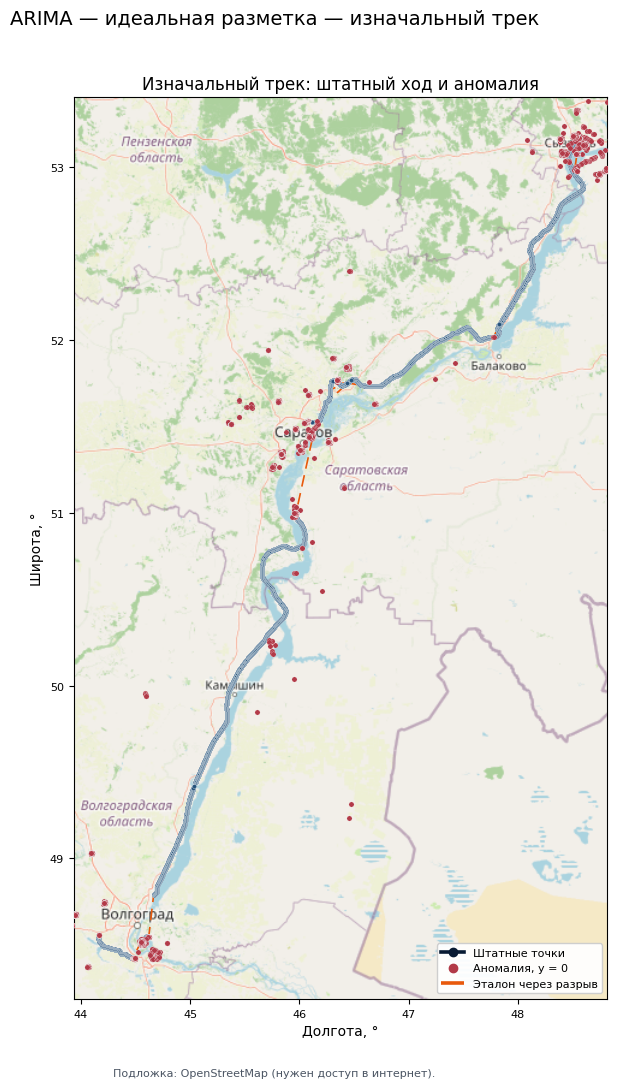


df1 (rho=60%)


,Сценарий,"RMSE, м","Max(d_i), м","Distance loss, м","Delay median, с","Delay mean, с","Delay p95, с","Delay max, с",On-time episodes,Late/missed episodes,Precision,Recall,F1
0,df1 (rho=60%),354_728.53,1_286_980.01,36_679_628.58,3_090,11_465.4,32_053.25,78_437,9,20,0.3460,0.6049,0.4402


  Карта разметки модели: последние 50 000 точек теста (bbox: move + 5%)


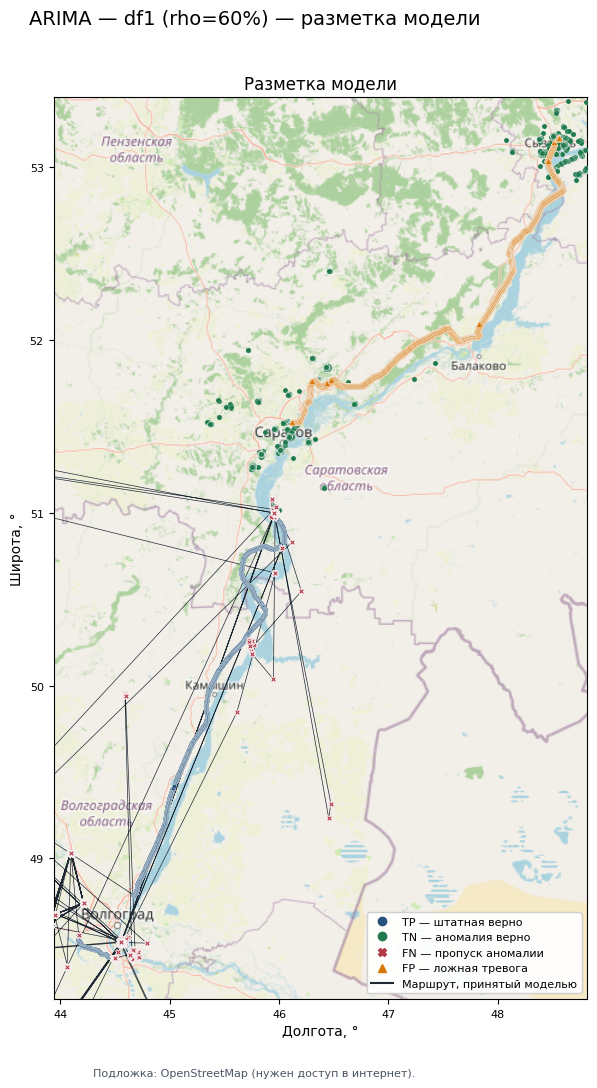


df2 (rho=80%)


,Сценарий,"RMSE, м","Max(d_i), м","Distance loss, м","Delay median, с","Delay mean, с","Delay p95, с","Delay max, с",On-time episodes,Late/missed episodes,Precision,Recall,F1
0,df2 (rho=80%),652_061.92,6_086_738.96,38_499_286.04,—,—,—,—,13,0,0.3097,0.9997,0.4729


  Карта разметки модели: последние 50 000 точек теста (bbox: move + 5%)


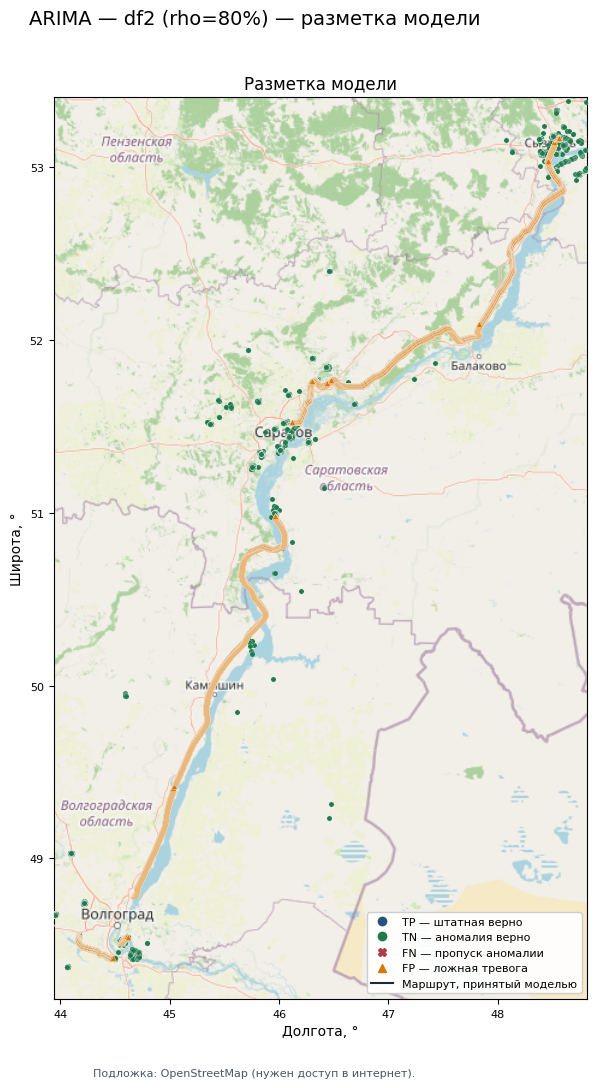

In [5]:
def arima_trend_for_order(order: tuple[int, int, int]) -> str:
    """trend для statsmodels: при d>0 нужен 't', не 'c'.

    Args:
        order: (p, d, q).

    Returns:
        str: 't' или 'c'.
    """
    return "t" if order[1] > 0 else "c"


def fit_arima_series(series: np.ndarray, order: tuple[int, int, int]):
    """Оценивает ARIMA на всём переданном ряду.

    Args:
        series: Одномерный ряд координаты.
        order: Порядок (p, d, q).

    Returns:
        Результат .fit() statsmodels.
    """
    model = ARIMA(
        np.asarray(series, dtype=np.float64),
        order=order,
        trend=arima_trend_for_order(order),
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    return model.fit()


def arima_one_step_levels(series: np.ndarray, fit_result, order: tuple[int, int, int]) -> np.ndarray:
    """Причинные одношаговые прогнозы уровня ряда.

    Args:
        series: Координата ENU.
        fit_result: Обученная модель (параметры с train).
        order: Порядок ARIMA.

    Returns:
        np.ndarray: Прогноз уровня той же длины, что series.
    """
    series = np.asarray(series, dtype=np.float64)
    model = ARIMA(
        series,
        order=order,
        trend=arima_trend_for_order(order),
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    filtered = model.filter(fit_result.params)
    prediction = filtered.get_prediction(start=0, end=len(series) - 1, dynamic=True)
    predicted = np.asarray(prediction.predicted_mean, dtype=np.float64)
    predicted[0] = series[0]
    return np.nan_to_num(predicted, nan=series[0])


def arima_enu_scores(
    east_m: np.ndarray,
    north_m: np.ndarray,
    fit_east,
    fit_north,
    order: tuple[int, int, int],
) -> np.ndarray:
    """Score в метрах ENU: гипотенуза ошибок прогноза x и n.

    Args:
        east_m: Восток.
        north_m: Север.
        fit_east: Модель по x с train.
        fit_north: Модель по n с train.
        order: Порядок ARIMA.

    Returns:
        np.ndarray: Скалярный score на каждой точке.
    """
    east_hat = arima_one_step_levels(east_m, fit_east, order)
    north_hat = arima_one_step_levels(north_m, fit_north, order)
    return np.hypot(np.asarray(east_m, dtype=float) - east_hat, np.asarray(north_m, dtype=float) - north_hat)



ARIMA_ORDER = (2, 1, 1)

SCENARIOS = (
    (f"df1 (rho={TEST_SPLIT_1:.0%})", df1),
    (f"df2 (rho={TEST_SPLIT_2:.0%})", df2),
)

arima_rows: list[dict[str, object]] = []
scenario_results: list[dict[str, object]] = []

for scenario_name, bundle in SCENARIOS:
    train = bundle["train"]
    test = bundle["test"]
    anomaly_train = train["y"].astype(str).to_numpy() == "anomaly"

    print("=" * 72)
    print(scenario_name)
    started = time.perf_counter()
    fit_east = fit_arima_series(train["x"].to_numpy(dtype=float), ARIMA_ORDER)
    fit_north = fit_arima_series(train["n"].to_numpy(dtype=float), ARIMA_ORDER)
    train_scores = arima_enu_scores(
        train["x"].to_numpy(dtype=float),
        train["n"].to_numpy(dtype=float),
        fit_east,
        fit_north,
        ARIMA_ORDER,
    )
    selection = select_anomaly_threshold(train, train_scores, MCC_BAND)
    if np.any(~anomaly_train) and np.any(anomaly_train):
        print(
            f"  медиана score на train: move {np.median(train_scores[~anomaly_train]):.4g}, "
            f"anomaly {np.median(train_scores[anomaly_train]):.4g}"
        )
    print(
        f"  порог {selection['tau']:.4g} м: MCC train {selection['train_mcc']:.4f} "
        f"(лучший {selection['best_mcc']:.4f}, в полосе {int(selection['band_size'])}), "
        f"DL train {selection['train_dl_m'] / 1000:.4f} км"
    )

    test_scores = arima_enu_scores(
        test["x"].to_numpy(dtype=float),
        test["n"].to_numpy(dtype=float),
        fit_east,
        fit_north,
        ARIMA_ORDER,
    )
    predicted_test = test_scores > selection["tau"]
    metrics = evaluate_test(test, predicted_test)
    elapsed = time.perf_counter() - started

    arima_rows.append(test_report_row(scenario_name, metrics))
    scenario_results.append(
        {
            "name": scenario_name,
            "test": test,
            "predicted_test": predicted_test,
            "metrics": metrics,
        }
    )

summary = pd.DataFrame(arima_rows)
report_columns = ["Сценарий"] + [key for key, _ in TEST_REPORT_METRICS]
display_test_report_table(
    summary.loc[:, report_columns],
    caption="ARIMA(2,1,1): сводные метрики на test (Отчёт.tex, раздел «Список метрик»)",
)

_ideal_test = scenario_results[0]["test"]
_map_tail = min(PLOT_TAIL, len(_ideal_test))
print(f"\nИдеальная разметка: последние {nfmt(_map_tail)} точек теста df1 (bbox: move + 5%)")
_dummy_move = np.zeros(len(_ideal_test), dtype=bool)
_truth_pred, _truth_gt = trajectory_series_pair(_ideal_test, _dummy_move)
_truth_pred = slice_trajectory_series(_truth_pred, _map_tail)
_truth_gt = slice_trajectory_series(_truth_gt, _map_tail)
plot_track_maps(
    _truth_pred,
    _truth_gt,
    map_panel="ground_truth",
    title="ARIMA — идеальная разметка",
    figsize=MAP_FIGSIZE,
    annotate=False,
)

for item in scenario_results:
    tail = min(PLOT_TAIL, len(item["test"]))
    print(f"\n{item['name']}")
    display_test_report_table(
        pd.DataFrame([test_report_row(str(item["name"]), item["metrics"])]).loc[:, report_columns],
        caption=f"Метрики test: {item['name']}",
    )
    print(f"  Карта разметки модели: последние {nfmt(tail)} точек теста (bbox: move + 5%)")
    prediction, ground_truth = trajectory_series_pair(item["test"], item["predicted_test"])
    prediction = slice_trajectory_series(prediction, tail)
    ground_truth = slice_trajectory_series(ground_truth, tail)
    plot_track_maps(
        prediction,
        ground_truth,
        map_panel="model",
        title=f"ARIMA — {item['name']}",
        figsize=MAP_FIGSIZE,
        annotate=False,
    )
